# Application: reduced proper motion diagram beyond Gaia (paper figure)

Paper figure `writeup/plots/rpm_diagram.pdf` (Section "An application" of `writeup/main.tex`) and the numbers quoted there.
The full pilot (selection checks, held-out field, vetting of the white-dwarf candidates) lives in `application/`
(`RPM_PILOT.md`); this notebook only reproduces the figure from the same code (`application/rpm.py`).

200 random bricks (12.5 deg$^2$) with centres in RA 25-35, Dec -40 to -30 ($b \approx -78^\circ$). Selection: clean
(`pm_quality == 0`) primary PSF objects with g, r, z, $\mu > 20$ mas/yr, $\mu/\sigma_\mu > 4$ and S/N$_r > 30$
(below that, the PM errors are underestimated and the 'high-PM' objects are mostly noise). Heavy I/O: run on a compute node.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

REPO = os.path.abspath('..')
sys.path.insert(0, REPO); sys.path.insert(0, os.path.join(REPO, 'application'))
from py_files import plot_style as ps
import rpm
ps.apply()
PLOTS = os.path.join(REPO, 'writeup', 'plots')

bricks = rpm.pick_bricks(rpm.find_bricks(ra_range=(25, 35), dec_range=(-40, -30)), 200, seed=1)
T = rpm.load(bricks)
d = rpm.derive(T)
gaia = d['gaia']
sel = rpm.hpm_mask(T, d, mu_min=20., snr_min=4., snr_r_min=30.)
area = len(bricks) * 0.0625
print(f'{len(bricks)} bricks, {area:.1f} deg2; {len(T):,} sources')
print(f'HPM: {sel.sum()} ({np.sum(sel & gaia)} Gaia, {np.sum(sel & ~gaia)} not in Gaia); '
      f'r range of non-Gaia {np.percentile(d["r"][sel & ~gaia], [5, 50, 95]).round(2)}')
for lo, hi in [(14, 21), (21, 22), (22, 23), (23, 30)]:
    m = sel & (d['r'] >= lo) & (d['r'] < hi)
    print(f'  r {lo}-{hi}: {m.sum():5d} HPM, {np.sum(m & gaia):5d} in Gaia')
n_all = rpm.hpm_mask(T, d, mu_min=20., snr_min=4., snr_r_min=0.).sum()
print(f'without the S/N limit: {n_all}')

200 bricks, 12.5 deg2; 2,031,131 sources
HPM: 7449 (5540 Gaia, 1909 not in Gaia); r range of non-Gaia [21.26 22.12 22.96]
  r 14-21:  4816 HPM,  4810 in Gaia
  r 21-22:  1479 HPM,   703 in Gaia
  r 22-23:  1086 HPM,    27 in Gaia
  r 23-30:    68 HPM,     0 in Gaia


without the S/N limit: 43402


In [2]:
# PM-direction test: real stars share the solar reflex motion, noise has random directions
pa = np.arctan2(T['pmra_no_plx'], T['pmdec_no_plx'])
ref = np.angle(np.mean(np.exp(1j * pa[sel & gaia])))
near = np.cos(pa - ref) > 0
pg = near[sel & gaia].mean()
low = rpm.hpm_mask(T, d, mu_min=20., snr_min=4., snr_r_min=15.) & (d['snr_r'] <= 30) & ~gaia
H40 = rpm.wd_track_H(d['g_z'], 40)
wd = sel & (d['g_z'] < 1.5) & (d['H_r'] > H40 - 1.5)
pw = near[wd & gaia].mean()
print(f'Gaia HPM within 90 deg of their mean direction: {pg:.2f}')
for lab, m, p in [('non-Gaia HPM, S/N_r > 30', sel & ~gaia, pg), ('non-Gaia, S/N_r 15-30 (excluded)', low, pg),
                  ('non-Gaia WD candidates (vs Gaia WD candidates)', wd & ~gaia, pw)]:
    f = near[m].mean()
    print(f'  {lab:48s} N={m.sum():5d}: {f:.2f} -> real fraction ~{(f - 0.5) / (p - 0.5):.2f} '
          f'+- {np.sqrt(f * (1 - f) / m.sum()) / (p - 0.5):.2f}')
print(f'WD candidates: {wd.sum()} ({np.sum(wd & gaia)} in Gaia, {np.sum(wd & ~gaia)} not = {np.sum(wd & ~gaia) / area:.1f} per deg2), '
      f'r of non-Gaia: {np.percentile(d["r"][wd & ~gaia], [5, 50, 95]).round(2)}')

Gaia HPM within 90 deg of their mean direction: 0.92
  non-Gaia HPM, S/N_r > 30                         N= 1909: 0.95 -> real fraction ~1.07 +- 0.01
  non-Gaia, S/N_r 15-30 (excluded)                 N=  643: 0.69 -> real fraction ~0.45 +- 0.04
  non-Gaia WD candidates (vs Gaia WD candidates)   N=  161: 0.81 -> real fraction ~1.11 +- 0.11
WD candidates: 235 (74 in Gaia, 161 not = 12.9 per deg2), r of non-Gaia: [21.31 22.1  23.11]


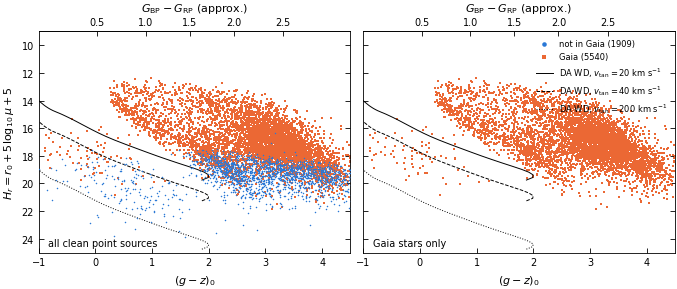

In [3]:
teff, gz_wd, Mr_wd = rpm.wd_tracks()['DA']
keep = (teff >= 3000) & (teff <= 30000)
rel_gz = rpm.gz_bprp_table()
VTANS = [(20, '-'), (40, '--'), (200, ':')]

def panel(ax, m, title):
    ax.scatter(d['g_z'][m & ~gaia], d['H_r'][m & ~gaia], s=1.2, marker=ps.MARKERS[0], color=ps.SERIES[0], lw=0,
               zorder=3, rasterized=True, label=f'not in Gaia ({np.sum(m & ~gaia)})')
    ax.scatter(d['g_z'][m & gaia], d['H_r'][m & gaia], s=1.2, marker=ps.MARKERS[1], color=ps.SERIES[1], lw=0,
               zorder=2, rasterized=True, label=f'Gaia ({np.sum(m & gaia)})')
    for v, ls in VTANS:
        ax.plot(gz_wd[keep], rpm.H_from_M(Mr_wd[keep], v), color='k', ls=ls, lw=0.7,
                label=rf'DA WD, $v_{{\rm tan}} = {v}$ km s$^{{-1}}$')
    ax.set_xlabel(r'$(g - z)_0$')
    rpm.add_bprp_axis(ax, rel_gz)
    ax.text(0.03, 0.03, title, transform=ax.transAxes, fontsize=7)

fig, axes = plt.subplots(1, 2, figsize=(ps.PAGE, 3.1), sharex=True, sharey=True)
panel(axes[0], sel, 'all clean point sources')
panel(axes[1], sel & gaia, 'Gaia stars only')
axes[0].set_ylabel(r'$H_r = r_0 + 5\log_{10}\mu + 5$')
axes[0].set_xlim(-1, 4.5); axes[0].set_ylim(25, 9)
h, l = axes[0].get_legend_handles_labels()
axes[1].legend(h, l, loc='upper right', markerscale=3, fontsize=6)
fig.tight_layout(w_pad=0.5)
fig.savefig(f'{PLOTS}/rpm_diagram.pdf', dpi=300)